# 02 — Complement Naive Bayes
Notebook thực nghiệm độc lập cho SecuraAI / Windows-APT 2025. Mọi lựa chọn được khóa bằng Train/Validation trước khi đánh giá Test.

## 0. Chuẩn bị môi trường
Chạy từ thư mục project hoặc thư mục `notebooks`. Không cần GPU.

In [29]:
from pathlib import Path
import json, hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import platform, sklearn
import importlib
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
    average_precision_score, confusion_matrix, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from securaai_ml.data import load_training_data
import securaai_ml.modeling as modeling_module
importlib.reload(modeling_module)  # tránh module cache cũ khi source vừa được cập nhật
from securaai_ml.modeling import (candidate_factories, decision_scores, parameter_grids,
    teaching_candidate_factories, teaching_parameter_grids)
from securaai_ml.schema import MODEL_FEATURES, TARGET_COLUMN, GROUP_COLUMN
from securaai_ml.train import temporal_train_validation_test

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data, audit = load_training_data(ROOT / 'data' / 'raw')
train, validation, test = temporal_train_validation_test(data)
X_train, y_train = train.loc[:, MODEL_FEATURES], train[TARGET_COLUMN]
X_validation, y_validation = validation.loc[:, MODEL_FEATURES], validation[TARGET_COLUMN]
groups = train[GROUP_COLUMN]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
audit

DatasetAudit(rows=102011, malicious=63792, benign=38219, groups=40, invalid_timestamps=0)

### Tính tái lập
Cố định seed và in phiên bản. Đổi seed là một thí nghiệm mới, không chọn seed bằng kết quả Test.

In [30]:
SEED=42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi':110,'font.family':'DejaVu Sans','font.size':10})
print('Python:',platform.python_version(),'| sklearn:',sklearn.__version__,'| seed:',SEED)

Python: 3.13.15 | sklearn: 1.7.0 | seed: 42


## 1. Xác thực dữ liệu và ý nghĩa nhãn
Nhãn MALICIOUS_APT được suy ra từ MITRE/Wazuh tag, không phải ground truth do chuyên gia xét duyệt. Các cột tạo nhãn bị loại khỏi đầu vào.

In [31]:
display(pd.Series(audit.__dict__,name='value').to_frame())
assert audit.rows==len(data)
assert data[TARGET_COLUMN].nunique()==2
assert data[GROUP_COLUMN].ne('unknown-date').all()
print('Dataset checks passed')

,value
rows,102011
malicious,63792
benign,38219
groups,40
invalid_timestamps,0


Dataset checks passed


## 2. Chia Train/Validation/Test và dấu vân tay
Chia xấp xỉ 60/20/20 theo ngày; không có ngày nào xuất hiện ở hai tập.

In [32]:
split_table=pd.DataFrame([{'set':name,'rows':len(part),'benign':int((part[TARGET_COLUMN]==0).sum()),'malicious':int((part[TARGET_COLUMN]==1).sum()),'attack_rate':float(part[TARGET_COLUMN].mean()),'dates':part[GROUP_COLUMN].nunique()} for name,part in [('Train',train),('Validation',validation),('Test',test)]])
display(split_table)
assert set(train[GROUP_COLUMN]).isdisjoint(validation[GROUP_COLUMN])
assert set(train[GROUP_COLUMN]).isdisjoint(test[GROUP_COLUMN])
assert set(validation[GROUP_COLUMN]).isdisjoint(test[GROUP_COLUMN])
split_hash=hashlib.sha256(json.dumps({'train':sorted(train[GROUP_COLUMN].unique()),'validation':sorted(validation[GROUP_COLUMN].unique()),'test':sorted(test[GROUP_COLUMN].unique())},sort_keys=True).encode()).hexdigest()
print('Split hash:',split_hash[:16])

,set,rows,benign,malicious,attack_rate,dates
0,Train,61277,20250,41027,0.669533,31
1,Validation,20176,9118,11058,0.548077,2
2,Test,20558,8851,11707,0.569462,7


Split hash: a94bf5446c1c1c5d


## 3. EDA chỉ trên Train
Quan sát mất cân bằng và tỷ lệ tấn công theo nhóm sự kiện mà không dùng Test để định hướng mô hình.

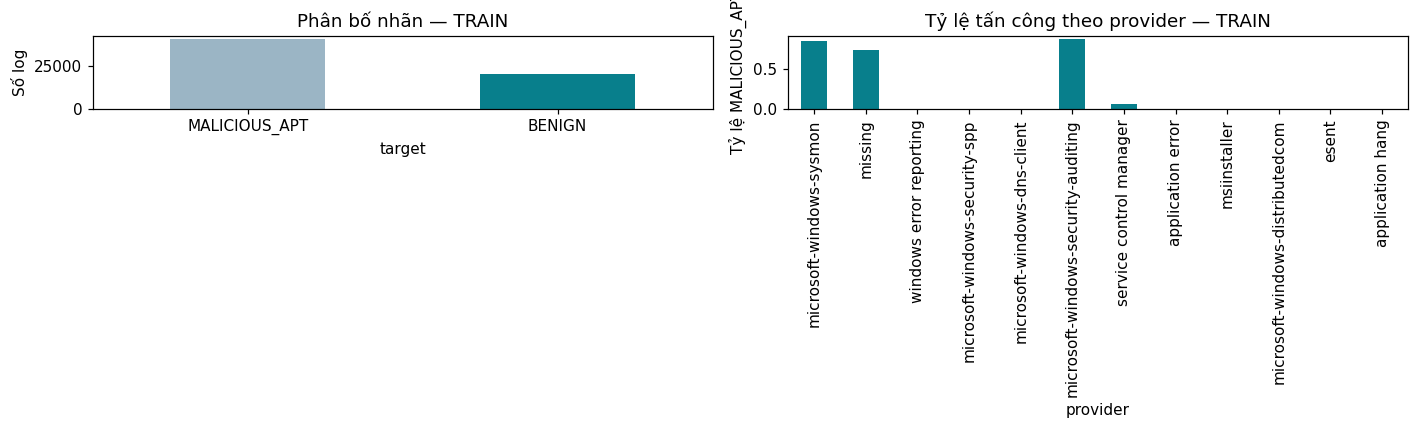

,count,mean
provider,,
microsoft-windows-sysmon,38378,0.846970
missing,9296,0.729561
windows error reporting,3172,0.000000
microsoft-windows-security-spp,2833,0.000000
microsoft-windows-dns-client,2744,0.000000
microsoft-windows-security-auditing,1841,0.868550
service control manager,927,0.060410
application error,525,0.000000
msiinstaller,404,0.000000


In [33]:
fig,ax=plt.subplots(1,2,figsize=(13,4))
train[TARGET_COLUMN].map({0:'BENIGN',1:'MALICIOUS_APT'}).value_counts().plot.bar(ax=ax[0],rot=0,color=['#9bb5c5','#087f8c']); ax[0].set_title('Phân bố nhãn — TRAIN'); ax[0].set_ylabel('Số log')
provider_rate=train.groupby('provider')[TARGET_COLUMN].agg(['count','mean']).query('count >= 100').sort_values('count',ascending=False).head(12)
provider_rate['mean'].plot.bar(ax=ax[1],color='#087f8c'); ax[1].set_title('Tỷ lệ tấn công theo provider — TRAIN'); ax[1].set_ylabel('Tỷ lệ MALICIOUS_APT')
plt.tight_layout(); plt.show(); display(provider_rate)

## 4. Cơ chế thuật toán và phạm vi triển khai
Mô hình xác suất với giả định feature độc lập có điều kiện. ComplementNB phù hợp ma trận One-Hot không âm; tuning hệ số làm trơn `alpha`.

## 5. Tiền xử lý an toàn trong Pipeline
One-Hot Encoder được fit bên trong từng fold. Không fit preprocessing trên toàn bộ dữ liệu trước CV.

In [34]:
candidate=teaching_candidate_factories(SEED)['naive_bayes']()
print(candidate)
print('Parameter grid:',teaching_parameter_grids()['naive_bayes'])

Pipeline(steps=[('preprocess',
                 ColumnTransformer(sparse_threshold=1.0,
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                min_frequency=2),
                                                  ['event_id', 'provider',
                                                   'channel', 'severity_value',
                                                   'decoder', 'location',
                                                   'input_type', 'logon_type',
                                                   'auth_package',
                                                   'integrity_level',
                                                   'process_name',
                                                   'parent_process_name',
                                                   'protocol', 'event_status',
           

## 6. Độ đo và Dummy baseline
Accuracy có thể gây hiểu nhầm. F2 nhấn mạnh Recall; ROC-AUC đo xếp hạng; AP hữu ích khi mất cân bằng.

In [35]:
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
dummy_pred=dummy.predict(X_validation); dummy_score=dummy.predict_proba(X_validation)[:,1]
display(pd.Series({'accuracy':accuracy_score(y_validation,dummy_pred),'precision':precision_score(y_validation,dummy_pred,zero_division=0),'recall':recall_score(y_validation,dummy_pred,zero_division=0),'f1':f1_score(y_validation,dummy_pred,zero_division=0),'f2':fbeta_score(y_validation,dummy_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_validation,dummy_score),'average_precision':average_precision_score(y_validation,dummy_score)},name='Dummy — Validation').to_frame())

,Dummy — Validation
accuracy,0.548077
precision,0.548077
recall,1.000000
f1,0.708075
f2,0.858434
roc_auc,0.500000
average_precision,0.548077


## 7. Chọn siêu tham số bằng 5-Fold chỉ trên Train
Grid Search chấm F2, F1, ROC-AUC và AP; `refit='f2'` khóa tiêu chí lựa chọn trước khi xem Test.

In [36]:
model_name = 'naive_bayes'
search = GridSearchCV(
    teaching_candidate_factories(42)[model_name](),
    teaching_parameter_grids()[model_name],
    scoring={'f2': make_scorer(fbeta_score, beta=2, zero_division=0),
             'f1': 'f1', 'roc_auc': 'roc_auc', 'average_precision': 'average_precision'},
    refit='f2',
    cv=cv, n_jobs=1, return_train_score=True,
)
search.fit(X_train, y_train, groups=groups)
print('Best parameters:', search.best_params_)
print('Mean CV F2:', search.best_score_)
model = search.best_estimator_

Best parameters: {'model__alpha': 0.1}
Mean CV F2: 0.01167714824593263


In [37]:
cv_table=pd.DataFrame(search.cv_results_).sort_values('rank_test_f2')
display(cv_table[['params','mean_train_f2','mean_test_f2','std_test_f2','mean_test_roc_auc','mean_test_average_precision']].head(12))

,params,mean_train_f2,mean_test_f2,std_test_f2,mean_test_roc_auc,mean_test_average_precision
0,{'model__alpha': 0.1},0.011929,0.011677,0.008291,0.969992,0.986717
1,{'model__alpha': 1.0},0.011913,0.011677,0.008291,0.956675,0.980656
2,{'model__alpha': 5.0},0.011913,0.011677,0.008291,0.939876,0.973066


## 8. Đánh giá trên Validation
Confusion Matrix cho biết TN/FP/FN/TP. ROC và PR phải dùng score liên tục, không dùng nhãn 0/1 đã cắt.

,Validation
accuracy,0.455046
precision,1.000000
recall,0.005697
f1,0.011330
f2,0.007111
roc_auc,0.971210
average_precision,0.977319


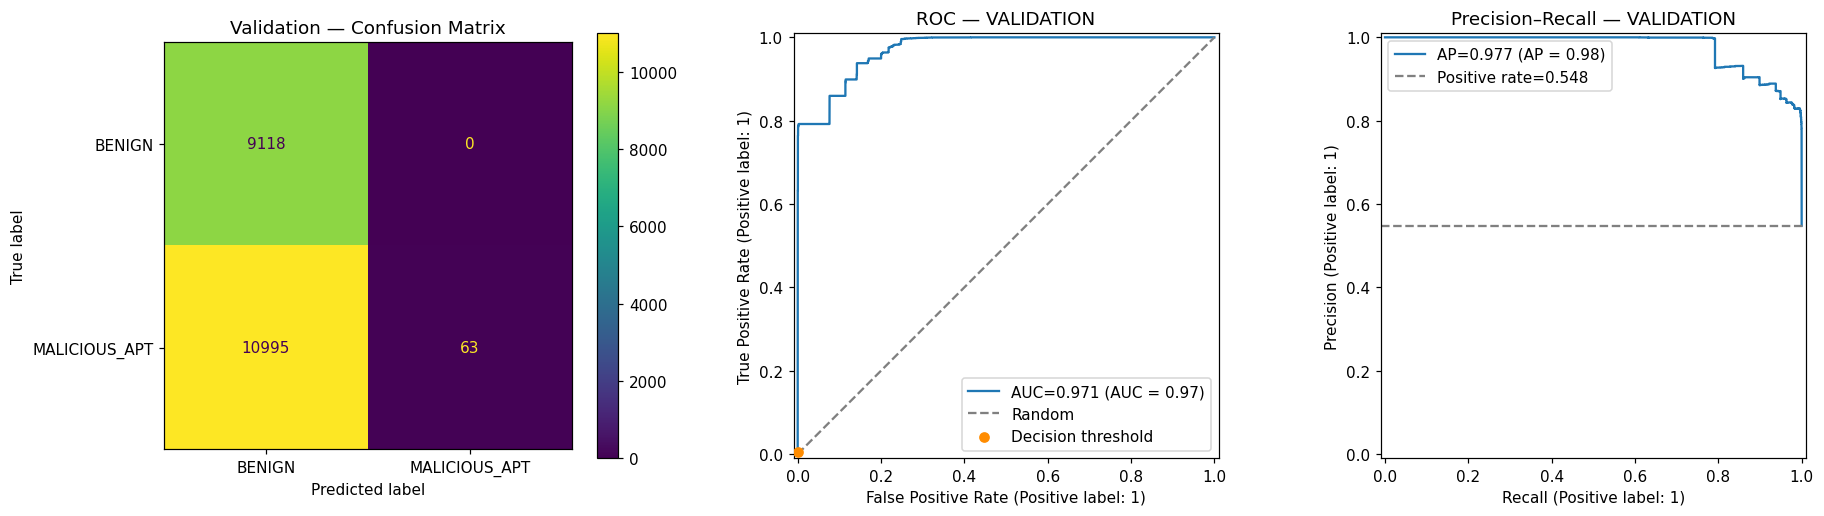

In [38]:
pred = model.predict(X_validation)
score = decision_scores(model, X_validation)
result = pd.Series({
    'accuracy': accuracy_score(y_validation, pred),
    'precision': precision_score(y_validation, pred, zero_division=0),
    'recall': recall_score(y_validation, pred, zero_division=0),
    'f1': f1_score(y_validation, pred, zero_division=0),
    'f2': fbeta_score(y_validation, pred, beta=2, zero_division=0),
    'roc_auc': roc_auc_score(y_validation, score),
    'average_precision': average_precision_score(y_validation, score),
})
display(result.to_frame('Validation'))
tn, fp, fn, tp = confusion_matrix(y_validation, pred, labels=[0, 1]).ravel()
fpr_at_threshold = fp / (fp + tn)
tpr_at_threshold = tp / (tp + fn)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay.from_predictions(y_validation, pred, display_labels=['BENIGN','MALICIOUS_APT'], ax=axes[0])
axes[0].set_title('Validation — Confusion Matrix')
RocCurveDisplay.from_predictions(y_validation, score, name=f"AUC={result['roc_auc']:.3f}", ax=axes[1])
axes[1].plot([0, 1], [0, 1], '--', color='gray', label='Random')
axes[1].scatter([fpr_at_threshold], [tpr_at_threshold], color='darkorange', zorder=5, label='Decision threshold')
axes[1].set_title('ROC — VALIDATION'); axes[1].legend()
PrecisionRecallDisplay.from_predictions(y_validation, score, name=f"AP={result['average_precision']:.3f}", ax=axes[2])
base_rate = float(y_validation.mean())
axes[2].axhline(base_rate, ls='--', color='gray', label=f'Positive rate={base_rate:.3f}')
axes[2].set_title('Precision–Recall — VALIDATION'); axes[2].legend()
plt.tight_layout(); plt.show()

## 10. Chọn và khóa ngưỡng trên Validation
Quét các phân vị score, chọn F2 cao nhất rồi khóa. Không điều chỉnh lại sau khi xem Test.

,threshold,precision,recall,f1,f2
19,2.389751e-42,0.825810,0.995931,0.902927,0.956521
18,7.164428e-44,0.816023,0.997558,0.897705,0.955065
17,2.315710e-45,0.804136,0.998734,0.890933,0.952627
16,3.709758e-47,0.793195,0.999277,0.884389,0.949917
20,2.041848e-41,0.828900,0.983541,0.899624,0.948163
21,8.240474e-41,0.838375,0.979924,0.903640,0.947915
15,2.328594e-48,0.782639,0.999638,0.877929,0.947118
22,1.312816e-39,0.843615,0.970790,0.902746,0.942378
14,1.461645e-49,0.755604,0.999819,0.860724,0.939114
23,1.470203e-38,0.851227,0.962923,0.903636,0.938299


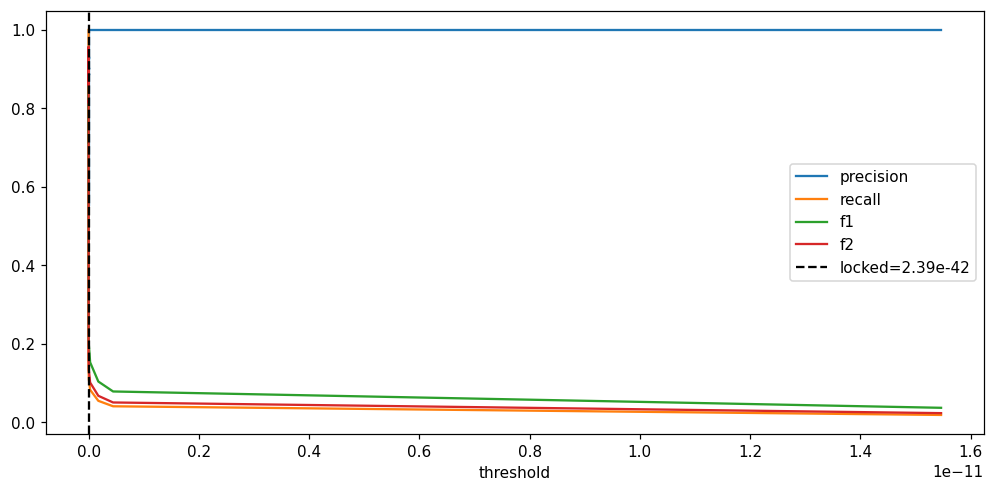

In [39]:
validation_score=decision_scores(model,X_validation)
threshold_grid=np.unique(np.quantile(validation_score,np.linspace(0.01,0.99,99)))
threshold_rows=[]
for threshold in threshold_grid:
    p=(validation_score>=threshold).astype(int)
    threshold_rows.append({'threshold':float(threshold),'precision':precision_score(y_validation,p,zero_division=0),'recall':recall_score(y_validation,p,zero_division=0),'f1':f1_score(y_validation,p,zero_division=0),'f2':fbeta_score(y_validation,p,beta=2,zero_division=0)})
threshold_table=pd.DataFrame(threshold_rows)
chosen=threshold_table.sort_values(['f2','recall','precision'],ascending=False).iloc[0]
locked_threshold=float(chosen.threshold)
display(threshold_table.sort_values('f2',ascending=False).head(10))
threshold_table.plot(x='threshold',y=['precision','recall','f1','f2'],figsize=(11,5)); plt.axvline(locked_threshold,color='black',ls='--',label=f'locked={locked_threshold:.4g}'); plt.legend(); plt.show()

## 11. Đánh giá Test đúng một lần
Siêu tham số và ngưỡng đã khóa. Kết quả Test chỉ dùng báo cáo cuối, không quay lại sửa thiết kế.

,TEST
accuracy,0.813698
precision,0.796507
recall,0.903733
f1,0.846739
f2,0.880039
roc_auc,0.946905
average_precision,0.965554


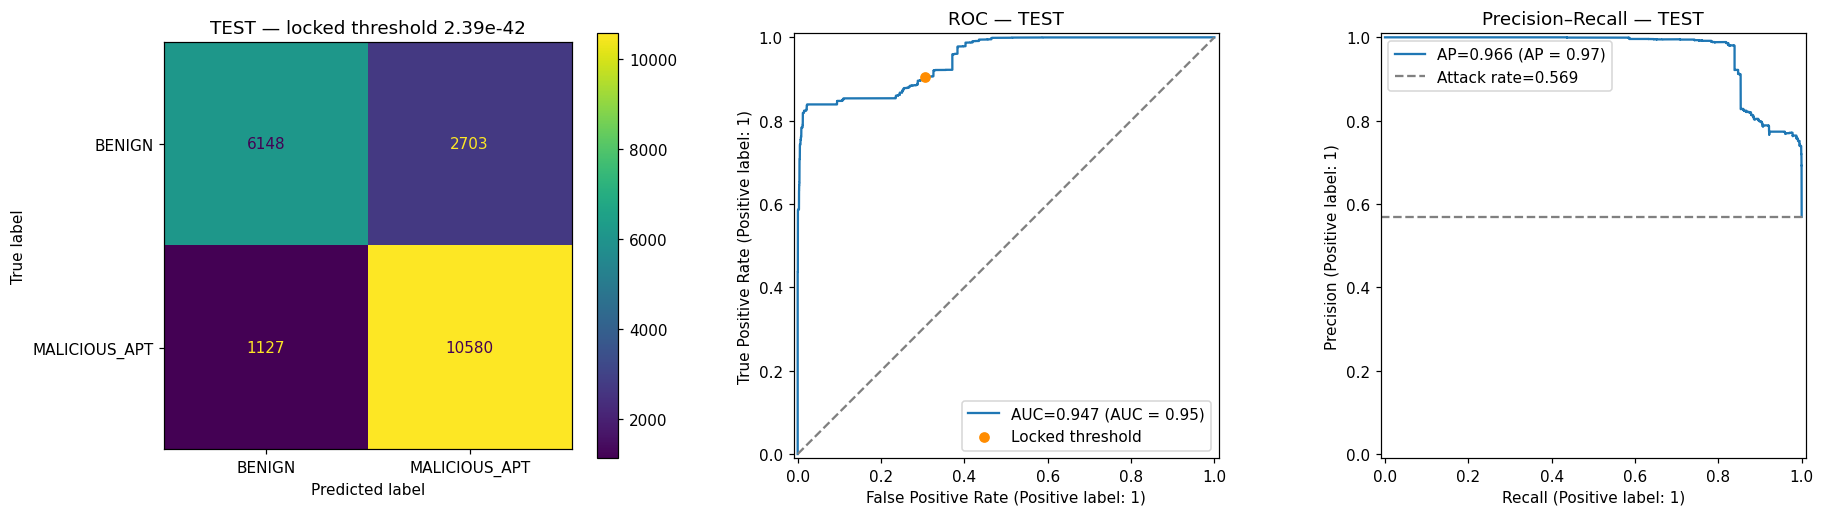

In [40]:
X_test,y_test=test.loc[:,MODEL_FEATURES],test[TARGET_COLUMN]
test_score=decision_scores(model,X_test)
test_pred=(test_score>=locked_threshold).astype(int)
test_result=pd.Series({'accuracy':accuracy_score(y_test,test_pred),'precision':precision_score(y_test,test_pred,zero_division=0),'recall':recall_score(y_test,test_pred,zero_division=0),'f1':f1_score(y_test,test_pred,zero_division=0),'f2':fbeta_score(y_test,test_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_test,test_score),'average_precision':average_precision_score(y_test,test_score)})
display(test_result.to_frame('TEST'))
tn,fp,fn,tp=confusion_matrix(y_test,test_pred,labels=[0,1]).ravel()
fig,axes=plt.subplots(1,3,figsize=(17,4.8))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['BENIGN','MALICIOUS_APT'],ax=axes[0]); axes[0].set_title(f'TEST — locked threshold {locked_threshold:.4g}')
RocCurveDisplay.from_predictions(y_test,test_score,name=f"AUC={test_result['roc_auc']:.3f}",ax=axes[1]); axes[1].plot([0,1],[0,1],'--',color='gray'); axes[1].scatter([fp/(fp+tn)],[tp/(tp+fn)],color='darkorange',zorder=5,label='Locked threshold'); axes[1].set_title('ROC — TEST'); axes[1].legend()
PrecisionRecallDisplay.from_predictions(y_test,test_score,name=f"AP={test_result['average_precision']:.3f}",ax=axes[2]); axes[2].axhline(float(y_test.mean()),ls='--',color='gray',label=f'Attack rate={y_test.mean():.3f}'); axes[2].set_title('Precision–Recall — TEST'); axes[2].legend(); plt.tight_layout(); plt.show()

## 12. Khoảng bất định bằng bootstrap
Bootstrap trên Test chỉ để mô tả độ bất định, không huấn luyện hoặc chọn ngưỡng lại.

In [41]:
rng=np.random.default_rng(SEED); boot=[]
y_array=y_test.to_numpy()
for _ in range(300):
    idx=rng.integers(0,len(y_array),len(y_array))
    if np.unique(y_array[idx]).size<2: continue
    boot.append({'f2':fbeta_score(y_array[idx],test_pred[idx],beta=2,zero_division=0),'roc_auc':roc_auc_score(y_array[idx],test_score[idx]),'average_precision':average_precision_score(y_array[idx],test_score[idx])})
boot=pd.DataFrame(boot)
display(pd.DataFrame({'estimate':test_result[['f2','roc_auc','average_precision']], 'ci_2.5%':boot.quantile(.025), 'ci_97.5%':boot.quantile(.975)}))

,estimate,ci_2.5%,ci_97.5%
f2,0.880039,0.875791,0.884305
roc_auc,0.946905,0.944703,0.949487
average_precision,0.965554,0.963874,0.967281


## 13. Lưu kết quả thực nghiệm
Lưu model, ngưỡng, split hash và metric để notebook so sánh tổng hợp có thể kiểm tra nguồn gốc.

In [42]:
experiment_dir=ROOT/'reports'/'notebook_experiments'; experiment_dir.mkdir(parents=True,exist_ok=True)
slug='02_naive_bayes'
joblib.dump(model,experiment_dir/f'{slug}.joblib')
record={'model':model_name,'best_params':search.best_params_,'cv_best_f2':float(search.best_score_),'locked_threshold':locked_threshold,'split_hash':split_hash,'validation':{k:float(v) for k,v in result.items()},'test':{k:float(v) for k,v in test_result.items()}}
(experiment_dir/f'{slug}.json').write_text(json.dumps(record,indent=2),encoding='utf-8')
record

{'model': 'naive_bayes',
 'best_params': {'model__alpha': 0.1},
 'cv_best_f2': 0.01167714824593263,
 'locked_threshold': 2.3897510762680362e-42,
 'split_hash': 'a94bf5446c1c1c5dfd396f631915ee856feabe56a8892eb656b3c234ee7239a8',
 'validation': {'accuracy': 0.45504559873116573,
  'precision': 1.0,
  'recall': 0.0056972327726532825,
  'f1': 0.01132991637442676,
  'f2': 0.007111412123264477,
  'roc_auc': 0.9712103256946135,
  'average_precision': 0.9773192438242231},
 'test': {'accuracy': 0.8136978305282615,
  'precision': 0.7965068132199051,
  'recall': 0.9037328094302554,
  'f1': 0.8467386954781913,
  'f2': 0.8800385952654256,
  'roc_auc': 0.9469046582991324,
  'average_precision': 0.9655544482451845}}

## 14. Kết luận
So sánh chính thức ở `08_Lua_Chon_Mo_Hinh_Va_Bao_Cao.ipynb`. Giới hạn: nhãn rule-derived, dữ liệu mô phỏng Windows APT và chưa phải bằng chứng hiệu năng production.